# Estimação de Parâmetros do Alimentador do Belvedere — com e sem ruído de medição

Estima a matriz de impedância trifásica do trecho do alimentador real do Belvedere (Cuiabá, modelado por BDGD + OpenDSS)
`[r11, r12, r22, r13, r23, r33, x11, x12, x22, x13, x23, x33]`
seguindo a mesma lógica usada para o IEEE 13 barras (`Estima.ipynb`, `ComRuido.ipynb` e `Estima_Ruido.ipynb`).

**Dados** (nesta pasta): três planilhas com uma aba por nível de perturbação dos parâmetros:

| Arquivo | Abas |
|---|---|
| `0_0_09_resultados_perturbacoes_potencia.xlsx` | `pert_0`, `pert_0.01` … `pert_0.09` |
| `0_1_0_19_resultados_perturbacoes_potencia.xlsx` | `pert_0`, `pert_0.10` … `pert_0.19` |
| `0_2_0_29_resultados_perturbacoes_potencia.xlsx` | `pert_0`, `pert_0.20` … `pert_0.29` |

Cada aba tem 10 000 fluxos de potência. Em `pert_p`, os 12 parâmetros variam em torno do nominal com desvio-padrão
relativo $\approx p$ (verificado na seção 1); `pert_0` não tem variação e não é usada.

**Roteiro**
1. Carga dos dados e escolha das features (mesma lógica do 13 barras: P e Q nos dois terminais, tensões e correntes no terminal de entrada).
2. Ruído de medição: mesmo modelo de `ComRuido.ipynb` (µPMU aleatória + TIs sistemáticos, D'Antona et al., IEEE TIM, 2026; P e Q com ±20 %).
3. Análise completa no nível `PERT = 0.01`, o mesmo do dataset do 13 barras: validação cruzada sem e com ruído, referência pela média, resíduos fora da amostra, hold-out e TIs não vistos no treino.
4. Varredura de todos os níveis de perturbação (0,01 a 0,29) com Ridge e ExtraTrees.

In [1]:
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

SEED = 42
PERT = 0.01   # nível usado na análise completa (mesmo do dataset do 13 barras)


def mape_per_target(y_true, y_pred):
    # MAPE (%) calculado coluna a coluna.
    return np.mean(np.abs((y_true - y_pred) / y_true), axis=0) * 100


def rmse_pct_per_target(y_true, y_pred):
    # RMSE normalizado pela média do target (%), coluna a coluna.
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2, axis=0))
    return rmse / np.mean(np.abs(y_true), axis=0) * 100


def run_cv(models, X, y, n_splits=3):
    # KFold-CV para todos os modelos. Retorna MAPE, RMSE% e predições OOF por target.
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    cv_results = {}
    for name, model in models.items():
        t0 = time.time()
        mape_folds, oof_pred = [], np.zeros_like(y, dtype=float)
        for train_idx, val_idx in cv.split(X):
            pipe = Pipeline([('scaler', StandardScaler()), ('model', clone(model))])
            pipe.fit(X[train_idx], y[train_idx])
            y_hat = pipe.predict(X[val_idx])
            oof_pred[val_idx] = y_hat
            mape_folds.append(mape_per_target(y[val_idx], y_hat))
            del pipe
            gc.collect()
        mape_folds = np.array(mape_folds)
        cv_results[name] = {
            'mape_mean': mape_folds.mean(axis=0),
            'mape_std':  mape_folds.std(axis=0),
            'rmse_pct':  rmse_pct_per_target(y, oof_pred),
            'r2':        r2_score(y, oof_pred, multioutput='raw_values'),
            'oof_pred':  oof_pred,
        }
        print(f'  {name:16s} MAPE={mape_folds.mean():.4f}%  '
              f'RMSE%={cv_results[name]["rmse_pct"].mean():.4f}%  '
              f'R²={cv_results[name]["r2"].mean():.4f}  ({time.time() - t0:.0f} s)')
    return cv_results


def mean_baseline_cv(y, n_splits=3):
    # Referência: prevê, em cada fold, a média dos targets do treino (mesmos folds de run_cv).
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    mape_folds, oof_pred = [], np.zeros_like(y, dtype=float)
    for train_idx, val_idx in cv.split(y):
        y_hat = np.tile(y[train_idx].mean(axis=0), (len(val_idx), 1))
        oof_pred[val_idx] = y_hat
        mape_folds.append(mape_per_target(y[val_idx], y_hat))
    return {'mape_mean': np.mean(mape_folds, axis=0),
            'rmse_pct':  rmse_pct_per_target(y, oof_pred),
            'r2':        r2_score(y, oof_pred, multioutput='raw_values')}

## 1. Carga dos dados e escolha das features

In [2]:
FILES = {
    0: '0_0_09_resultados_perturbacoes_potencia.xlsx',
    1: '0_1_0_19_resultados_perturbacoes_potencia.xlsx',
    2: '0_2_0_29_resultados_perturbacoes_potencia.xlsx',
}
LEVELS = [round(0.01 * k, 2) for k in range(1, 30)]   # 0,01 … 0,29


def load_level(p):
    # Lê a aba pert_p da planilha correspondente.
    return pd.read_excel(FILES[int(round(p * 100)) // 10], sheet_name=f'pert_{p:.2f}')


df_clean = load_level(PERT)
print(f'Nível {PERT}: shape {df_clean.shape}')
print(df_clean.columns.tolist())

Nível 0.01: shape (10000, 54)
['r11', 'r12', 'r22', 'r13', 'r23', 'r33', 'x11', 'x12', 'x22', 'x13', 'x23', 'x33', 'P_Term1', 'Q_Term1', 'P_Term1_Norm', 'Q_Term1_Norm', 'P_Term1_Emerg', 'Q_Term1_Emerg', 'P_Term2', 'Q_Term2', 'V1_mag_59911939827572667mt', 'V1_ang_59911939827572667mt', 'V1_pu_59911939827572667mt', 'V2_mag_59911939827572667mt', 'V2_ang_59911939827572667mt', 'V2_pu_59911939827572667mt', 'V3_mag_59911939827572667mt', 'V3_ang_59911939827572667mt', 'V3_pu_59911939827572667mt', 'V1_mag_59912191827572000mt', 'V1_ang_59912191827572000mt', 'V1_pu_59912191827572000mt', 'V2_mag_59912191827572000mt', 'V2_ang_59912191827572000mt', 'V2_pu_59912191827572000mt', 'V3_mag_59912191827572000mt', 'V3_ang_59912191827572000mt', 'V3_pu_59912191827572000mt', 'I1_mag_faseA', 'I1_ang_faseA', 'I1_mag_faseB', 'I1_ang_faseB', 'I1_mag_faseC', 'I1_ang_faseC', 'I2_mag_faseA', 'I2_ang_faseA', 'I2_mag_faseB', 'I2_ang_faseB', 'I2_mag_faseC', 'I2_ang_faseC', 'desvio_P1_Terminal_1', 'desvio_P2_Terminal_2', '

In [3]:
TARGETS = ['r11', 'r12', 'r22', 'r13', 'r23', 'r33',
           'x11', 'x12', 'x22', 'x13', 'x23', 'x33']

B1 = '59911939827572667mt'   # barra do terminal 1 (entrada)
B2 = '59912191827572000mt'   # barra do terminal 2 (saída)

# Grandezas medidas (sobre as quais o ruído é aplicado)
P_COLS     = ['P_Term1', 'Q_Term1', 'P_Term2', 'Q_Term2']
V_MAG_COLS = [f'V{k}_mag_{b}' for b in (B1, B2) for k in (1, 2, 3)]
V_ANG_COLS = [f'V{k}_ang_{b}' for b in (B1, B2) for k in (1, 2, 3)]
I_MAG_COLS = [f'I{t}_mag_fase{f}' for t in (1, 2) for f in 'ABC']
I_ANG_COLS = [f'I{t}_ang_fase{f}' for t in (1, 2) for f in 'ABC']

# Features: mesma lógica do 13 barras — P e Q nos dois terminais (aqui trifásicos),
# tensões e correntes apenas no terminal de entrada.
FEATURES = (P_COLS
            + [c for k in (1, 2, 3) for c in (f'V{k}_mag_{B1}', f'V{k}_ang_{B1}')]
            + [c for f in 'ABC' for c in (f'I1_mag_fase{f}', f'I1_ang_fase{f}')])

# Colunas não usadas: tensões em p.u. (redundantes com as magnitudes), P/Q _Norm e
# _Emerg (nulas) e as colunas desvio_* (não são medições).
print(f'Features ({len(FEATURES)}): {FEATURES}')
print(f'Targets  ({len(TARGETS)}): {TARGETS}')

Features (16): ['P_Term1', 'Q_Term1', 'P_Term2', 'Q_Term2', 'V1_mag_59911939827572667mt', 'V1_ang_59911939827572667mt', 'V2_mag_59911939827572667mt', 'V2_ang_59911939827572667mt', 'V3_mag_59911939827572667mt', 'V3_ang_59911939827572667mt', 'I1_mag_faseA', 'I1_ang_faseA', 'I1_mag_faseB', 'I1_ang_faseB', 'I1_mag_faseC', 'I1_ang_faseC']
Targets  (12): ['r11', 'r12', 'r22', 'r13', 'r23', 'r33', 'x11', 'x12', 'x22', 'x13', 'x23', 'x33']


In [4]:
# Variação relativa dos targets e das medições no nível escolhido
rel_std = (df_clean[TARGETS].std() / df_clean[TARGETS].mean() * 100).round(3)
print(f'Desvio-padrão relativo dos parâmetros em pert_{PERT:.2f} (%):')
display(rel_std.to_frame('σ/média (%)').T)

meas = P_COLS + V_MAG_COLS + I_MAG_COLS
print('\nDesvio-padrão relativo das medições (%) — a carga é praticamente fixa:')
display((df_clean[meas].std() / df_clean[meas].mean().abs() * 100).round(4).to_frame('σ/|média| (%)').T)

Desvio-padrão relativo dos parâmetros em pert_0.01 (%):


,r11,r12,r22,r13,r23,r33,x11,x12,x22,x13,x23,x33
σ/média (%),0.993,1.007,1.005,1.007,0.999,0.991,1.0,0.995,0.992,0.997,0.996,1.005



Desvio-padrão relativo das medições (%) — a carga é praticamente fixa:


,P_Term1,Q_Term1,P_Term2,Q_Term2,V1_mag_59911939827572667mt,V2_mag_59911939827572667mt,V3_mag_59911939827572667mt,V1_mag_59912191827572000mt,V2_mag_59912191827572000mt,V3_mag_59912191827572000mt,I1_mag_faseA,I1_mag_faseB,I1_mag_faseC,I2_mag_faseA,I2_mag_faseB,I2_mag_faseC
σ/|média| (%),0.0002,0.0003,0.0002,0.0002,0.0,0.0,0.0,0.0002,0.0002,0.0002,0.0002,0.0002,0.0002,0.0002,0.0002,0.0002


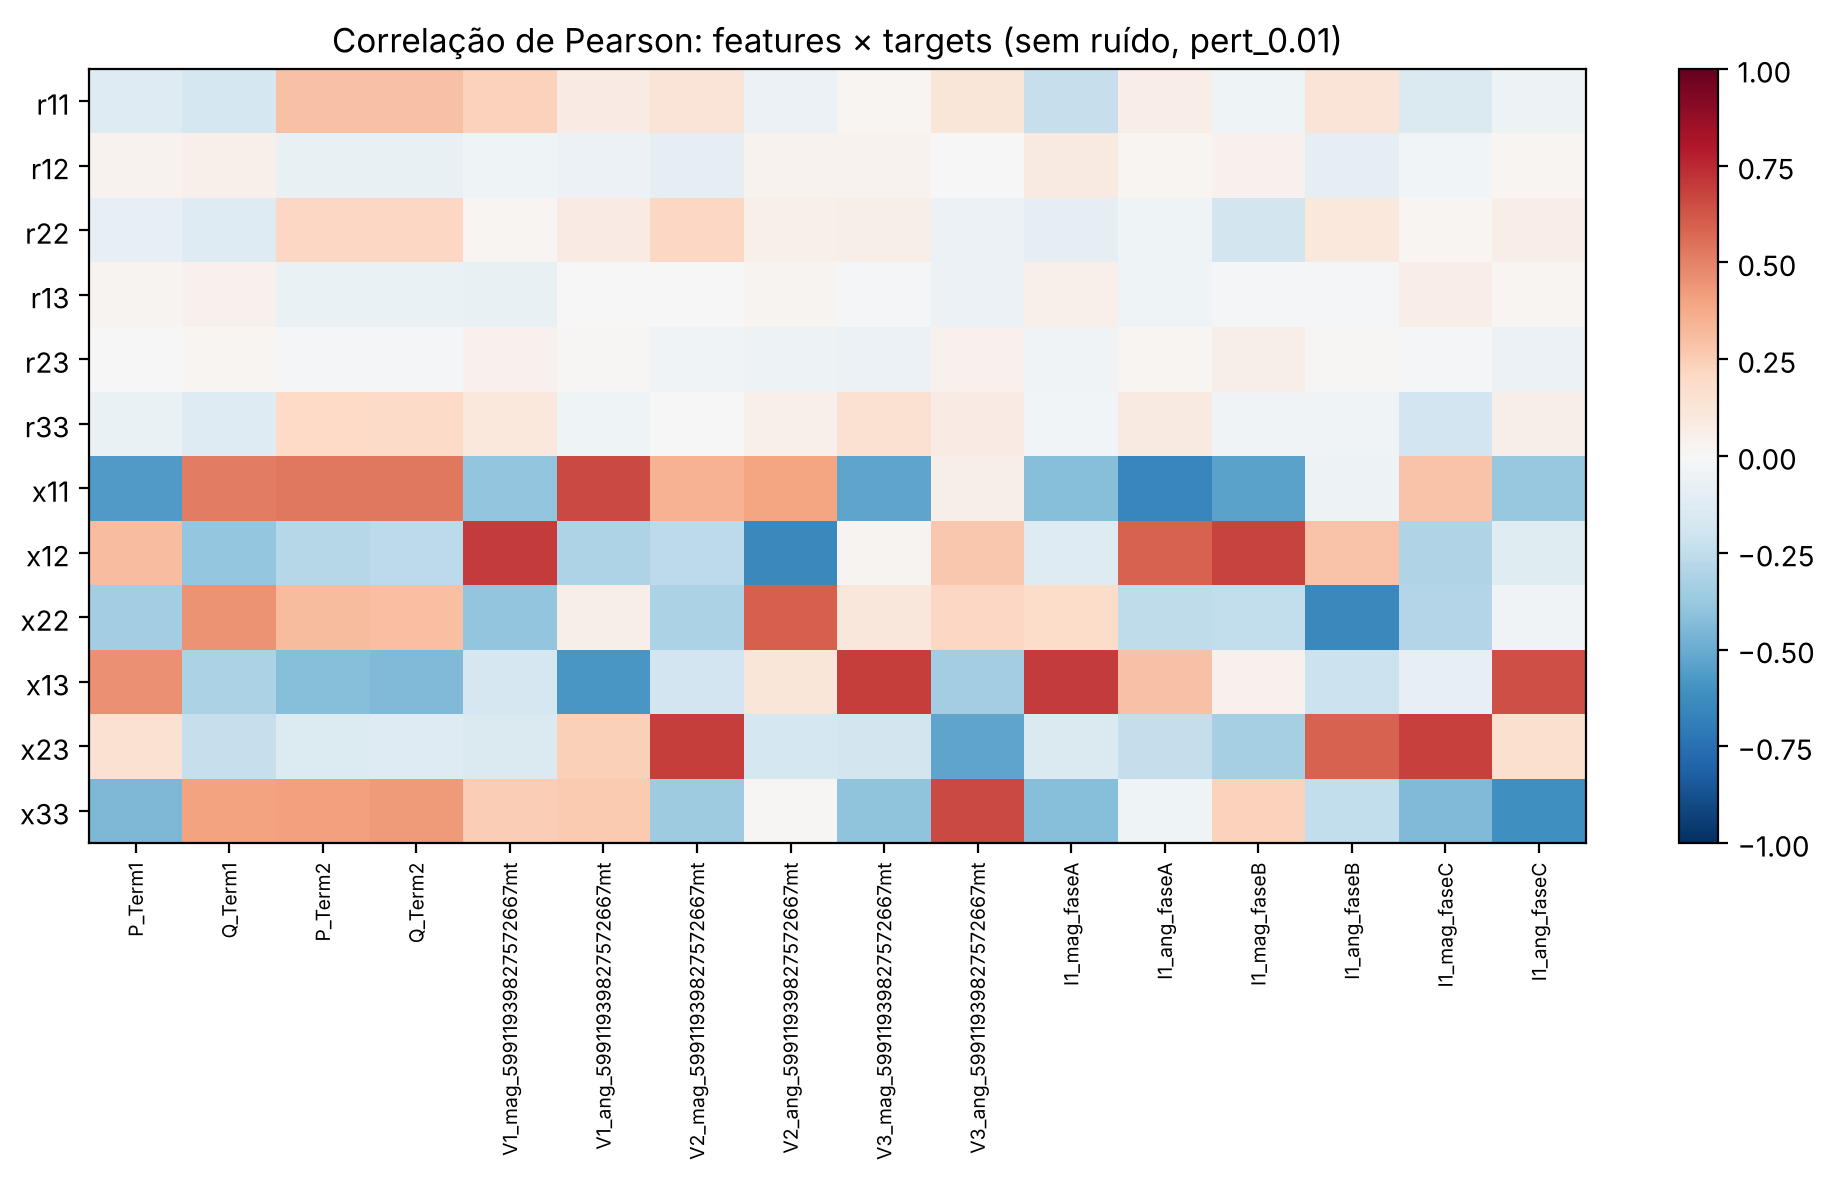

In [5]:
corr = df_clean[FEATURES + TARGETS].corr().loc[FEATURES, TARGETS]

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(corr.T.values, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(TARGETS)))
ax.set_yticklabels(TARGETS)
ax.set_title(f'Correlação de Pearson: features × targets (sem ruído, pert_{PERT:.2f})')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 2. Modelo de ruído de medição

Mesmo modelo de `ComRuido.ipynb` (D'Antona et al., IEEE TIM, 2026). Para o canal $c$ (grandeza × fase × terminal) e a amostra $n$:

- magnitude: $\hat{X}_c[n] = X_c[n]\,(1 + \varepsilon^{\mathrm{PMU}}_c[n] + b^{\mathrm{TI}}_c)$
- ângulo: $\hat{\theta}_c[n] = \theta_c[n] + \varepsilon^{\mathrm{PMU}}_c[n] + b^{\mathrm{TI}}_c$

| Fonte | Magnitude | Ângulo | Comportamento |
|---|---|---|---|
| µPMU | ±0,2 % | ±0,2 crad | aleatório, novo sorteio a cada amostra |
| TP classe 1 | ±1 % | ±1,2 crad | sistemático, um sorteio por canal (fixo) |
| TC classe 1 | ±1 % | ±1,8 crad | sistemático, um sorteio por canal (fixo) |
| P, Q (variação de carga) | ±20 % | — | aleatório, por amostra |

Todos os erros são uniformes. Os erros sistemáticos dos TIs correspondem a uma realização (`IT_SEED = 1`), a mesma para
todos os níveis de perturbação, pois os TIs instalados não mudam. Os valores sorteados são salvos em
`erros_sistematicos_TI_seed1.csv`.

In [6]:
CRAD_TO_DEG = 0.01 * 180 / np.pi   # 1 crad ≈ 0,5730°

PMU_MAG, PMU_ANG_DEG = 0.002, 0.2 * CRAD_TO_DEG
TP_MAG,  TP_ANG_DEG  = 0.010, 1.2 * CRAD_TO_DEG
TC_MAG,  TC_ANG_DEG  = 0.010, 1.8 * CRAD_TO_DEG
PQ_VAR = 0.20
IT_SEED = 1

# Limites dos erros sistemáticos por canal (magnitudes: fração; ângulos: graus)
IT_BOUNDS = ({c: (TP_MAG, 'TP') for c in V_MAG_COLS}
             | {c: (TP_ANG_DEG, 'TP') for c in V_ANG_COLS}
             | {c: (TC_MAG, 'TC') for c in I_MAG_COLS}
             | {c: (TC_ANG_DEG, 'TC') for c in I_ANG_COLS})


def draw_it_errors(seed):
    # Um sorteio por canal, na ordem V_mag, V_ang, I_mag, I_ang (como em ComRuido).
    rng_it = np.random.default_rng(seed)
    return {c: float(rng_it.uniform(-b, b)) for c, (b, _) in IT_BOUNDS.items()}


def add_noise(df, it_err, rng):
    # Aplica o ruído de medição (µPMU + TI) aos fasores e ±20 % a P e Q.
    out, n = df.copy(), len(df)
    for c in V_MAG_COLS + I_MAG_COLS:
        out[c] = df[c] * (1 + rng.uniform(-PMU_MAG, PMU_MAG, n) + it_err[c])
    for c in V_ANG_COLS + I_ANG_COLS:
        out[c] = df[c] + rng.uniform(-PMU_ANG_DEG, PMU_ANG_DEG, n) + it_err[c]
    for c in P_COLS:
        out[c] = df[c] * (1 + rng.uniform(-PQ_VAR, PQ_VAR, n))
    return out


def swap_it_errors(df_noisy, df_clean, it_old, it_new):
    # Troca a realização dos TIs mantendo o mesmo ruído da µPMU.
    out = df_noisy.copy()
    for c in V_MAG_COLS + I_MAG_COLS:
        out[c] = df_noisy[c] + df_clean[c] * (it_new[c] - it_old[c])
    for c in V_ANG_COLS + I_ANG_COLS:
        out[c] = df_noisy[c] + (it_new[c] - it_old[c])
    return out


it_err = draw_it_errors(IT_SEED)
pd.DataFrame([
    {'canal': c, 'fonte': IT_BOUNDS[c][1],
     'erro_sistematico': v * 100 if c in V_MAG_COLS + I_MAG_COLS else v / CRAD_TO_DEG,
     'unidade': '%' if c in V_MAG_COLS + I_MAG_COLS else 'crad',
     'limite': IT_BOUNDS[c][0] * 100 if c in V_MAG_COLS + I_MAG_COLS else IT_BOUNDS[c][0] / CRAD_TO_DEG}
    for c, v in it_err.items()
]).set_index('canal').to_csv(f'erros_sistematicos_TI_seed{IT_SEED}.csv')

df_noisy = add_noise(df_clean, it_err, np.random.default_rng(SEED))
print(f'Ruído aplicado; erros sistemáticos salvos em erros_sistematicos_TI_seed{IT_SEED}.csv')

Ruído aplicado; erros sistemáticos salvos em erros_sistematicos_TI_seed1.csv


In [7]:
# Verificação: em cada canal, o erro médio deve coincidir com o viés do TI e a
# dispersão em torno dele deve ser a da µPMU (σ = 0,2/√3 ≈ 0,1155 % ou crad).
rows = []
for c in V_MAG_COLS + V_ANG_COLS + I_MAG_COLS + I_ANG_COLS:
    if c in V_MAG_COLS + I_MAG_COLS:
        err, bias, unit = (df_noisy[c] / df_clean[c] - 1) * 100, it_err[c] * 100, '%'
    else:
        err, bias, unit = (df_noisy[c] - df_clean[c]) / CRAD_TO_DEG, it_err[c] / CRAD_TO_DEG, 'crad'
    rows.append({'canal': c, 'viés TI': round(bias, 4), 'erro médio': round(err.mean(), 4),
                 'σ': round(err.std(), 4), 'max |erro − viés|': round((err - bias).abs().max(), 4),
                 'unidade': unit})
display(pd.DataFrame(rows).set_index('canal'))

for c in P_COLS:
    e = (df_noisy[c] / df_clean[c] - 1) * 100
    print(f'{c:8s}: erro_max = {e.abs().max():.3f} %   σ = {e.std():.3f} %')

,viés TI,erro médio,σ,max |erro − viés|,unidade
canal,,,,,
V1_mag_59911939827572667mt,0.0236,0.0225,0.1153,0.2000,%
V2_mag_59911939827572667mt,0.9009,0.9021,0.1156,0.2000,%
V3_mag_59911939827572667mt,-0.7117,-0.7107,0.1154,0.2000,%
V1_mag_59912191827572000mt,0.8973,0.8980,0.1158,0.2000,%
V2_mag_59912191827572000mt,-0.3763,-0.3762,0.1152,0.2000,%
V3_mag_59912191827572000mt,-0.1533,-0.1535,0.1156,0.2000,%
V1_ang_59911939827572667mt,0.7865,0.7860,0.1153,0.1999,crad
V2_ang_59911939827572667mt,-0.2179,-0.2188,0.1151,0.2000,crad
V3_ang_59911939827572667mt,0.1190,0.1185,0.1159,0.2000,crad


P_Term1 : erro_max = 19.996 %   σ = 11.571 %
Q_Term1 : erro_max = 19.993 %   σ = 11.549 %
P_Term2 : erro_max = 19.999 %   σ = 11.584 %
Q_Term2 : erro_max = 19.999 %   σ = 11.464 %


## 3. Modelos (mesmos hiperparâmetros de `Estima_Ruido.ipynb`)

In [8]:
models = {
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': MultiOutputRegressor(
        RandomForestRegressor(n_estimators=100, max_depth=20, max_samples=0.8,
                              n_jobs=-1, random_state=SEED),
        n_jobs=-1),
    'ExtraTrees': MultiOutputRegressor(
        ExtraTreesRegressor(n_estimators=100, max_depth=20, n_jobs=-1, random_state=SEED),
        n_jobs=-1),
    'GradientBoosting': MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=100, max_depth=4, learning_rate=0.05,
                                  subsample=0.8, random_state=SEED),
        n_jobs=-1),
}

X_clean = df_clean[FEATURES].values
X_noisy = df_noisy[FEATURES].values
y = df_clean[TARGETS].values      # targets sempre sem ruído

## 4. Validação cruzada (3-fold) — sem ruído e com ruído

In [9]:
print(f'=== Sem ruído — pert_{PERT:.2f} ===')
cv_clean = run_cv(models, X_clean, y)
print(f'\n=== Com ruído — pert_{PERT:.2f} ===')
cv_noisy = run_cv(models, X_noisy, y)

=== Sem ruído — pert_0.01 ===


  Ridge            MAPE=0.6125%  RMSE%=0.7682%  R²=0.3855  (0 s)


  RandomForest     MAPE=0.6658%  RMSE%=0.8349%  R²=0.2889  (127 s)


  ExtraTrees       MAPE=0.6788%  RMSE%=0.8514%  R²=0.2608  (58 s)


  GradientBoosting MAPE=0.6515%  RMSE%=0.8172%  R²=0.3180  (66 s)

=== Com ruído — pert_0.01 ===


  Ridge            MAPE=0.7983%  RMSE%=1.0004%  R²=-0.0029  (0 s)


  RandomForest     MAPE=0.8037%  RMSE%=1.0070%  R²=-0.0163  (169 s)


  ExtraTrees       MAPE=0.8058%  RMSE%=1.0096%  R²=-0.0214  (67 s)


  GradientBoosting MAPE=0.8018%  RMSE%=1.0045%  R²=-0.0113  (61 s)


In [10]:
base = mean_baseline_cv(y)
rows = []
for name in models:
    rows.append({'Modelo': name,
                 'Sem ruído MAPE %': cv_clean[name]['mape_mean'].mean(),
                 'Sem ruído RMSE%':  cv_clean[name]['rmse_pct'].mean(),
                 'Sem ruído R²':     cv_clean[name]['r2'].mean(),
                 'Com ruído MAPE %': cv_noisy[name]['mape_mean'].mean(),
                 'Com ruído RMSE%':  cv_noisy[name]['rmse_pct'].mean(),
                 'Com ruído R²':     cv_noisy[name]['r2'].mean()})
rows.append({'Modelo': 'Média do treino (referência)',
             'Sem ruído MAPE %': base['mape_mean'].mean(), 'Sem ruído RMSE%': base['rmse_pct'].mean(),
             'Sem ruído R²': base['r2'].mean(),
             'Com ruído MAPE %': base['mape_mean'].mean(), 'Com ruído RMSE%': base['rmse_pct'].mean(),
             'Com ruído R²': base['r2'].mean()})
df_summary = pd.DataFrame(rows).set_index('Modelo').round(4)
print(f'Resumo — CV 3-fold, pert_{PERT:.2f}')
print('R² = 0 equivale a prever a média; um modelo só aprende algo útil se ficar abaixo da referência em MAPE/RMSE%.')
display(df_summary)

Resumo — CV 3-fold, pert_0.01
R² = 0 equivale a prever a média; um modelo só aprende algo útil se ficar abaixo da referência em MAPE/RMSE%.


,Sem ruído MAPE %,Sem ruído RMSE%,Sem ruído R²,Com ruído MAPE %,Com ruído RMSE%,Com ruído R²
Modelo,,,,,,
Ridge,0.6125,0.7682,0.3855,0.7983,1.0004,-0.0029
RandomForest,0.6658,0.8349,0.2889,0.8037,1.0070,-0.0163
ExtraTrees,0.6788,0.8514,0.2608,0.8058,1.0096,-0.0214
GradientBoosting,0.6515,0.8172,0.3180,0.8018,1.0045,-0.0113
Média do treino (referência),0.7974,0.9991,-0.0003,0.7974,0.9991,-0.0003


In [11]:
for label, res in [('Sem ruído', cv_clean), ('Com ruído', cv_noisy)]:
    print(f'\nMAPE % por target — {label}')
    df_t = pd.DataFrame({name: res[name]['mape_mean'] for name in models}, index=TARGETS)
    df_t['Média (ref.)'] = base['mape_mean']
    display(df_t.round(4))


MAPE % por target — Sem ruído


,Ridge,RandomForest,ExtraTrees,GradientBoosting,Média (ref.)
r11,0.5853,0.6188,0.6299,0.6044,0.7911
r12,0.7917,0.8127,0.8266,0.7972,0.8038
r22,0.6806,0.7120,0.7306,0.6977,0.7985
r13,0.7914,0.8090,0.8231,0.7976,0.8024
r23,0.7918,0.8074,0.8205,0.7955,0.7984
r33,0.6741,0.7008,0.7180,0.6856,0.7899
x11,0.5578,0.6050,0.6170,0.5888,0.7987
x12,0.4705,0.5722,0.5820,0.5562,0.7945
x22,0.5231,0.6070,0.6175,0.5914,0.7947
x13,0.5241,0.5760,0.5864,0.5615,0.7945



MAPE % por target — Com ruído


,Ridge,RandomForest,ExtraTrees,GradientBoosting,Média (ref.)
r11,0.7927,0.7961,0.7987,0.7953,0.7911
r12,0.8044,0.8113,0.8123,0.8078,0.8038
r22,0.8000,0.8041,0.8081,0.8020,0.7985
r13,0.8030,0.8100,0.8147,0.8083,0.8024
r23,0.7991,0.8060,0.8066,0.8043,0.7984
r33,0.7910,0.7952,0.7985,0.7940,0.7899
x11,0.8006,0.8063,0.8062,0.8052,0.7987
x12,0.7946,0.7971,0.7995,0.7968,0.7945
x22,0.7959,0.8004,0.8020,0.7998,0.7947
x13,0.7950,0.8005,0.8017,0.7972,0.7945


## 5. Melhor modelo com ruído — resíduos fora da amostra (OOF)

Melhor modelo com ruído (menor MAPE médio): Ridge


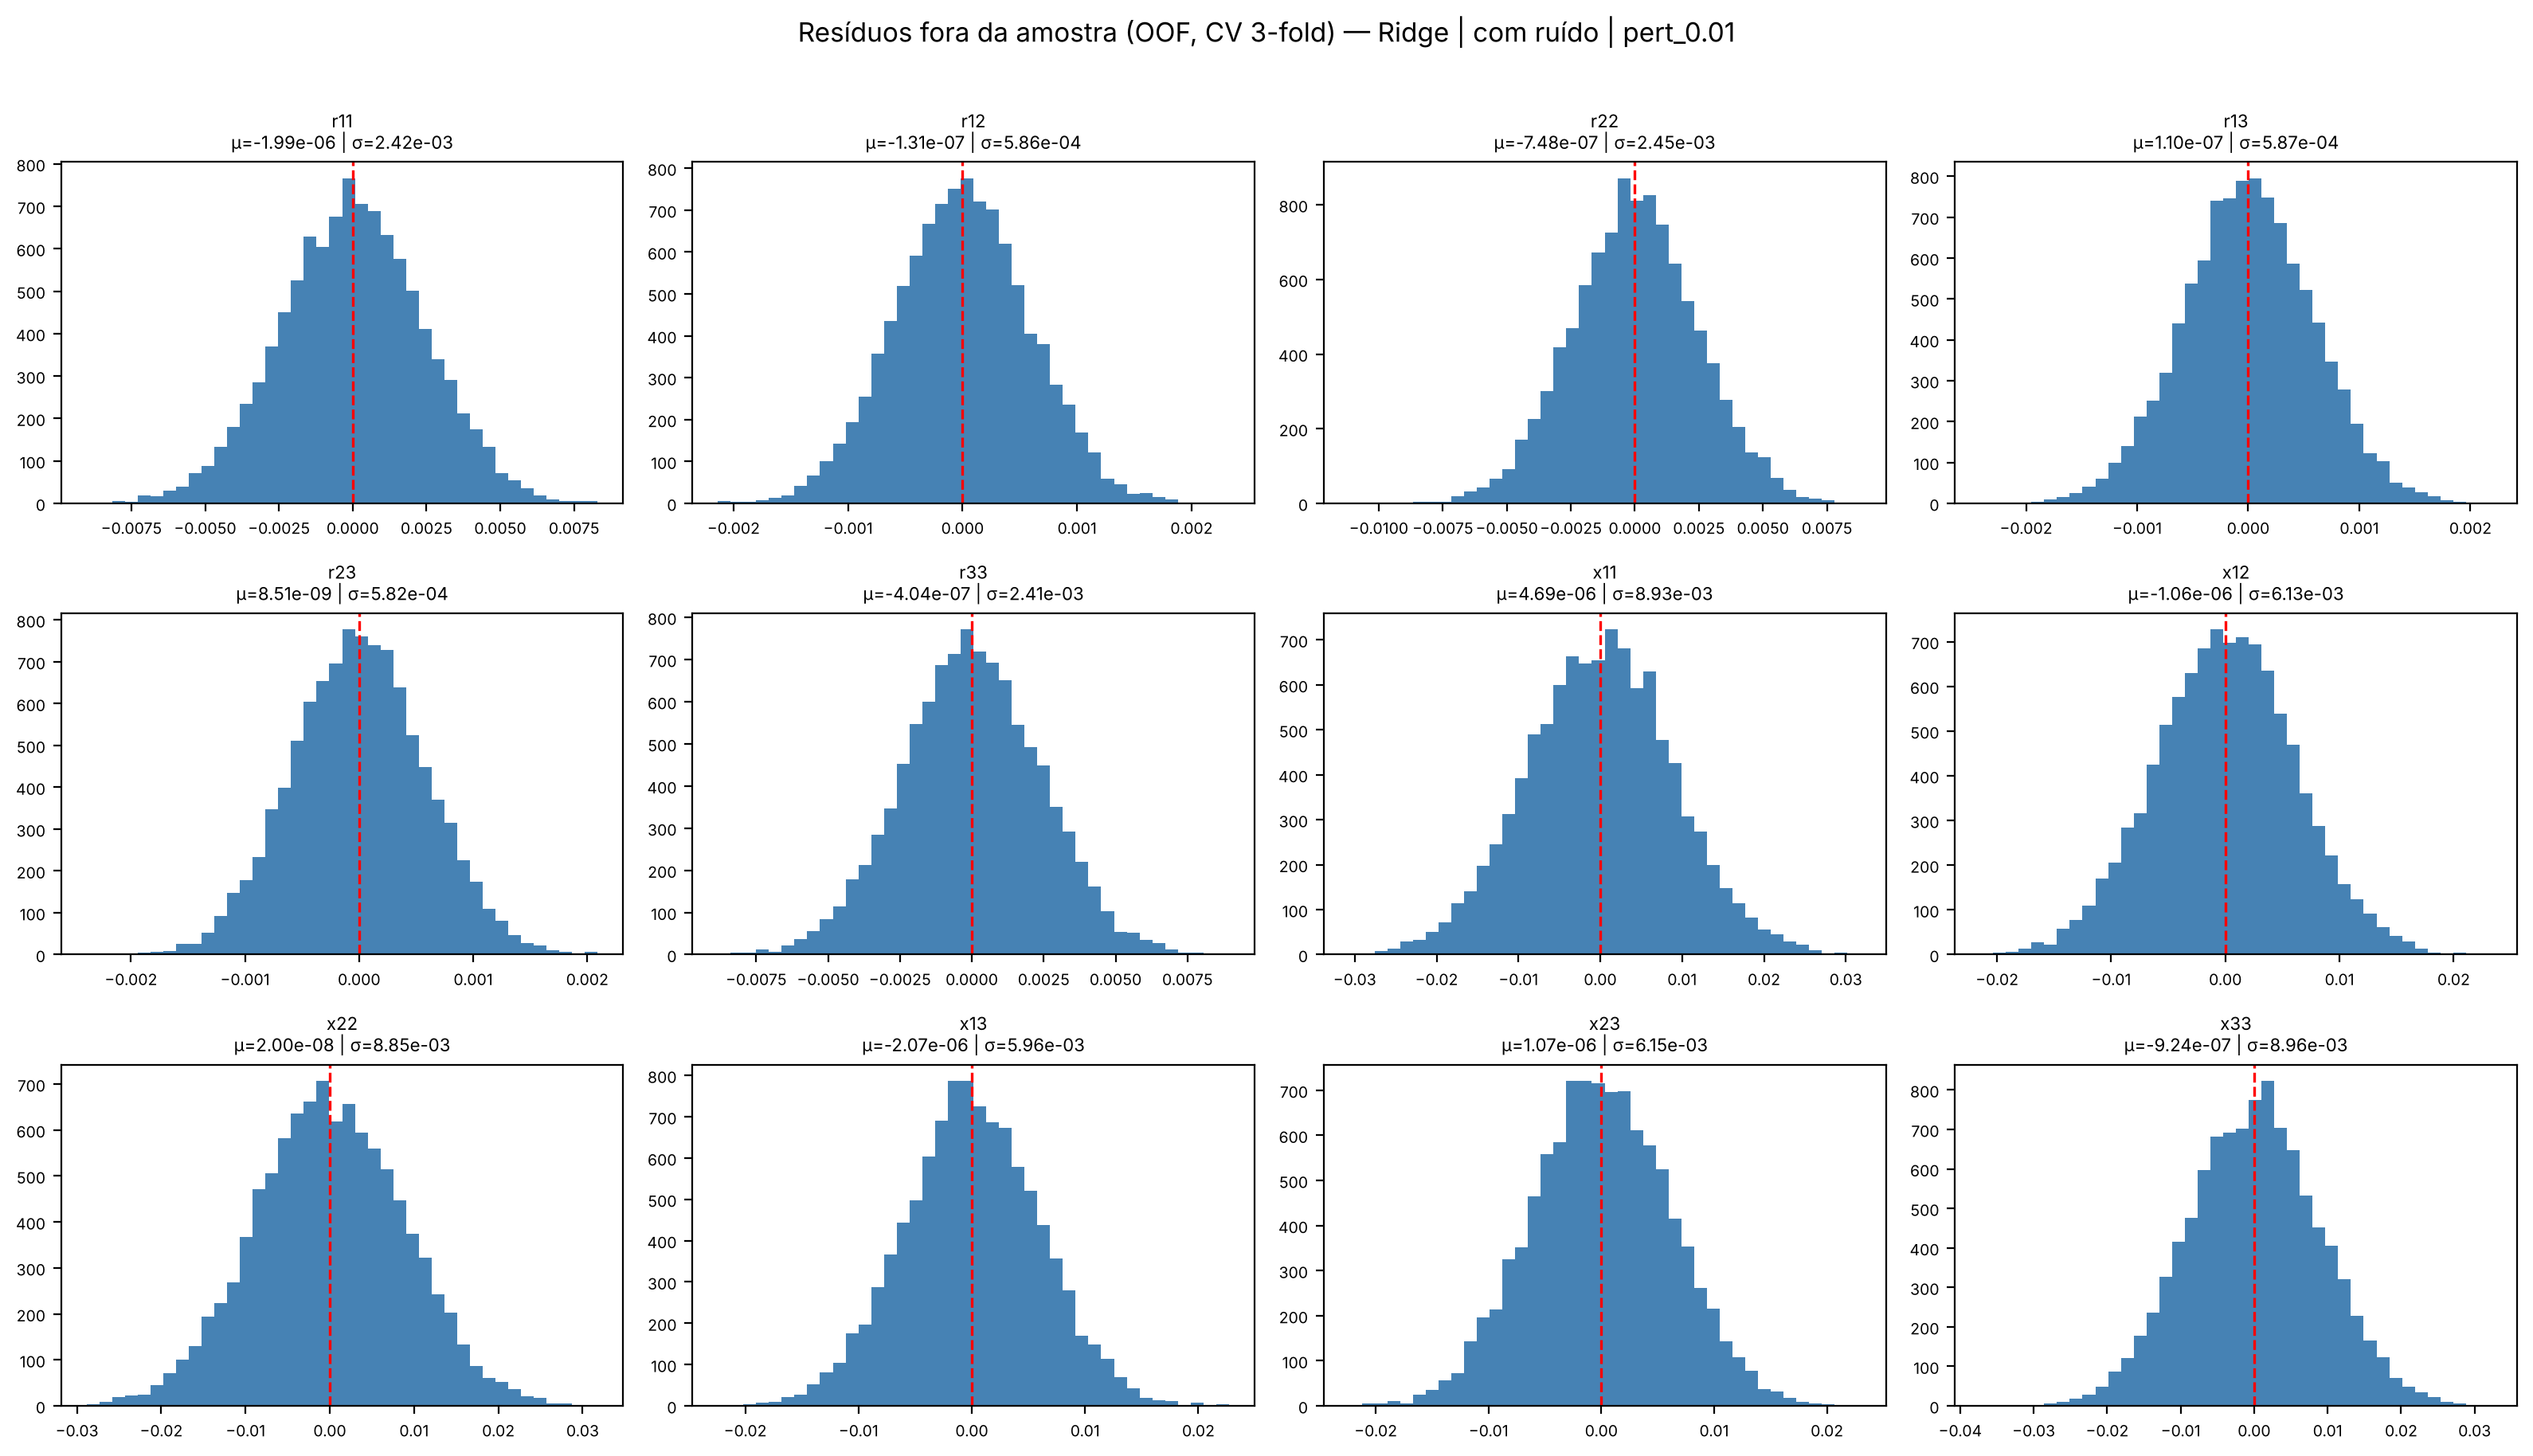

In [12]:
best_name = min(cv_noisy, key=lambda n: cv_noisy[n]['mape_mean'].mean())
print(f'Melhor modelo com ruído (menor MAPE médio): {best_name}')
residuals = y - cv_noisy[best_name]['oof_pred']

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for i, (ax, t) in enumerate(zip(axes.flatten(), TARGETS)):
    ax.hist(residuals[:, i], bins=40, color='steelblue', edgecolor='none')
    ax.axvline(0, color='red', lw=1.2, ls='--')
    ax.set_title(f'{t}\nμ={residuals[:, i].mean():.2e} | σ={residuals[:, i].std():.2e}', fontsize=8)
    ax.tick_params(labelsize=7)
plt.suptitle(f'Resíduos fora da amostra (OOF, CV 3-fold) — {best_name} | com ruído | pert_{PERT:.2f}',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 6. Hold-out 20 %

In [13]:
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED)
y_tr, y_te = y[idx_tr], y[idx_te]
y_ref = np.tile(y_tr.mean(axis=0), (len(idx_te), 1))

# Features de teste com TIs não vistos (seção 7): mesmas amostras e mesmo ruído da µPMU,
# erros sistemáticos dos TIs trocados por 10 novas realizações (IT_SEED = 2 … 11).
IT_TEST_SEEDS = list(range(2, 12))
X_unseen = {s: swap_it_errors(df_noisy, df_clean, it_err, draw_it_errors(s))[FEATURES].values[idx_te]
            for s in IT_TEST_SEEDS}

rows, rows_it = [], []
for label, X_ds in [('Sem ruído', X_clean), ('Com ruído', X_noisy)]:
    for name, model in models.items():
        pipe = Pipeline([('scaler', StandardScaler()), ('model', clone(model))])
        pipe.fit(X_ds[idx_tr], y_tr)
        y_hat = pipe.predict(X_ds[idx_te])
        rows.append({'Dataset': label, 'Modelo': name,
                     'MAPE %': mape_per_target(y_te, y_hat).mean(),
                     'RMSE%':  rmse_pct_per_target(y_te, y_hat).mean(),
                     'R²':     r2_score(y_te, y_hat)})
        if label == 'Com ruído':   # avaliação com TIs não vistos (seção 7)
            preds = [pipe.predict(X_unseen[s]) for s in IT_TEST_SEEDS]
            mape_u = [mape_per_target(y_te, h).mean() for h in preds]
            rows_it.append({'Modelo': name,
                            'MAPE % — mesmos TIs': mape_per_target(y_te, y_hat).mean(),
                            'MAPE % — TIs não vistos (média)': np.mean(mape_u),
                            'MAPE % — TIs não vistos (máx)': np.max(mape_u),
                            'R² — mesmos TIs': r2_score(y_te, y_hat),
                            'R² — TIs não vistos (média)': np.mean([r2_score(y_te, h) for h in preds])})
        del pipe                   # florestas profundas ocupam muita memória
        gc.collect()
    rows.append({'Dataset': label, 'Modelo': 'Média do treino (referência)',
                 'MAPE %': mape_per_target(y_te, y_ref).mean(),
                 'RMSE%':  rmse_pct_per_target(y_te, y_ref).mean(),
                 'R²':     r2_score(y_te, y_ref)})

df_holdout = pd.DataFrame(rows).set_index(['Dataset', 'Modelo']).round(4)
print(f'Hold-out 20 % — pert_{PERT:.2f}')
display(df_holdout)

Hold-out 20 % — pert_0.01


MAPE %   RMSE%      R²
Dataset   Modelo                                              
Sem ruído Ridge                         0.6147  0.7703  0.3836
          RandomForest                  0.6728  0.8429  0.2783
          ExtraTrees                    0.6856  0.8588  0.2505
          GradientBoosting              0.6564  0.8226  0.3120
          Média do treino (referência)  0.7993  1.0012 -0.0015
Com ruído Ridge                         0.7996  1.0019 -0.0029
          RandomForest                  0.8034  1.0076 -0.0143
          ExtraTrees                    0.8057  1.0099 -0.0191
          GradientBoosting              0.8020  1.0049 -0.0090
          Média do treino (referência)  0.7993  1.0012 -0.0015

## 7. Generalização para TIs não vistos no treino

Os modelos treinados com ruído na seção 6 (`IT_SEED = 1`) foram testados nas mesmas amostras de teste, com o mesmo
ruído da µPMU, mas com os erros sistemáticos dos TIs trocados por 10 novas realizações (`IT_SEED = 2 … 11`). É o
cenário de campo: os TIs instalados não são os usados para gerar os dados de treino.

In [14]:
m_ref, r_ref = mape_per_target(y_te, y_ref).mean(), r2_score(y_te, y_ref)
df_it_res = pd.DataFrame(rows_it + [{
    'Modelo': 'Média do treino (referência)',
    'MAPE % — mesmos TIs': m_ref, 'MAPE % — TIs não vistos (média)': m_ref,
    'MAPE % — TIs não vistos (máx)': m_ref,
    'R² — mesmos TIs': r_ref, 'R² — TIs não vistos (média)': r_ref}]).set_index('Modelo').round(4)
print(f'Hold-out 20 % — pert_{PERT:.2f} — treino com IT_SEED = 1; teste com 10 realizações de TIs não vistos')
display(df_it_res)

Hold-out 20 % — pert_0.01 — treino com IT_SEED = 1; teste com 10 realizações de TIs não vistos


,MAPE % — mesmos TIs,MAPE % — TIs não vistos (média),MAPE % — TIs não vistos (máx),R² — mesmos TIs,R² — TIs não vistos (média)
Modelo,,,,,
Ridge,0.7996,0.8426,0.8933,-0.0029,-0.1162
RandomForest,0.8034,0.8300,0.8416,-0.0143,-0.0816
ExtraTrees,0.8057,0.8123,0.8181,-0.0191,-0.0349
GradientBoosting,0.8020,0.9341,0.9910,-0.0090,-0.3713
Média do treino (referência),0.7993,0.7993,0.7993,-0.0015,-0.0015


## 8. Varredura do nível de perturbação dos parâmetros

Repete o hold-out 20 % para todos os níveis (0,01 a 0,29) com o modelo linear (Ridge) e uma árvore (ExtraTrees), sem
ruído, com ruído (mesmos TIs do treino) e com 10 realizações de TIs não vistos. O ruído da µPMU é sorteado de novo
para cada nível; os TIs são os mesmos (`IT_SEED = 1`).

Como a variação dos parâmetros é gaussiana com desvio-padrão relativo igual ao nível, os níveis mais altos contêm
alguns parâmetros **negativos** (ver a coluna `n_param_neg`), o que torna o MAPE instável. Por isso a varredura usa
RMSE% e R².

In [15]:
sweep_models = {'Ridge': models['Ridge'], 'ExtraTrees': models['ExtraTrees']}
rows = []
t0 = time.time()
for k, p in enumerate(LEVELS):
    d_clean = load_level(p)
    d_noisy = add_noise(d_clean, it_err, np.random.default_rng([SEED, k]))
    yp = d_clean[TARGETS].values
    Xc, Xn = d_clean[FEATURES].values, d_noisy[FEATURES].values
    Xu = {s: swap_it_errors(d_noisy, d_clean, it_err, draw_it_errors(s))[FEATURES].values
          for s in IT_TEST_SEEDS}
    i_tr, i_te = train_test_split(np.arange(len(yp)), test_size=0.2, random_state=SEED)
    y_ref = np.tile(yp[i_tr].mean(axis=0), (len(i_te), 1))
    row = {'nivel': p, 'n_param_neg': int((yp <= 0).sum()),
           'Média RMSE%': rmse_pct_per_target(yp[i_te], y_ref).mean()}
    for name, model in sweep_models.items():
        for label, X_ds in [('sem ruído', Xc), ('com ruído', Xn)]:
            pipe = Pipeline([('scaler', StandardScaler()), ('model', clone(model))])
            pipe.fit(X_ds[i_tr], yp[i_tr])
            y_hat = pipe.predict(X_ds[i_te])
            row[f'{name} {label} RMSE%'] = rmse_pct_per_target(yp[i_te], y_hat).mean()
            row[f'{name} {label} R²'] = r2_score(yp[i_te], y_hat)
        # TIs não vistos: modelo treinado com ruído (último pipe)
        y_hats = [pipe.predict(Xu[s][i_te]) for s in IT_TEST_SEEDS]
        row[f'{name} TIs não vistos RMSE%'] = np.mean([rmse_pct_per_target(yp[i_te], h).mean() for h in y_hats])
        row[f'{name} TIs não vistos R²'] = np.mean([r2_score(yp[i_te], h) for h in y_hats])
        del pipe
    rows.append(row)
    gc.collect()
    print(f'nível {p:.2f} concluído ({time.time() - t0:.0f} s)')

df_sweep = pd.DataFrame(rows).set_index('nivel')
df_sweep.to_csv('resultados_varredura_perturbacao.csv')
display(df_sweep.round(4))

nível 0.01 concluído (82 s)


nível 0.02 concluído (164 s)


nível 0.03 concluído (246 s)


nível 0.04 concluído (324 s)


nível 0.05 concluído (404 s)


nível 0.06 concluído (487 s)


... (20 outputs left out)

nível 0.27 concluído (2087 s)


nível 0.28 concluído (2161 s)


nível 0.29 concluído (2235 s)


,n_param_neg,Média RMSE%,Ridge sem ruído RMSE%,Ridge sem ruído R²,Ridge com ruído RMSE%,Ridge com ruído R²,Ridge TIs não vistos RMSE%,Ridge TIs não vistos R²,ExtraTrees sem ruído RMSE%,ExtraTrees sem ruído R²,ExtraTrees com ruído RMSE%,ExtraTrees com ruído R²,ExtraTrees TIs não vistos RMSE%,ExtraTrees TIs não vistos R²
nivel,,,,,,,,,,,,,,
0.01,0,1.0012,0.7703,0.3836,1.0019,-0.0029,1.0530,-0.1162,0.8588,0.2505,1.0099,-0.0191,1.0177,-0.0349
0.02,0,1.9870,1.5110,0.3947,1.9891,-0.0029,2.0994,-0.1234,1.6763,0.2729,2.0115,-0.0257,2.0183,-0.0329
0.03,0,2.9872,2.2919,0.3884,2.9903,-0.0026,3.1744,-0.1369,2.5492,0.2584,3.0175,-0.0209,3.0449,-0.0397
0.04,0,3.9747,3.0324,0.3943,3.9762,-0.0017,4.1925,-0.1199,3.3708,0.2678,4.0142,-0.0210,4.0513,-0.0402
0.05,0,5.0026,3.8240,0.3889,5.0062,-0.0020,5.2935,-0.1270,4.2551,0.2610,5.0575,-0.0226,5.0842,-0.0336
0.06,0,5.9858,4.5825,0.3903,5.9891,-0.0018,6.3827,-0.1469,5.1186,0.2558,6.0503,-0.0224,6.0969,-0.0384
0.07,0,7.0212,5.3614,0.3901,7.0256,-0.0022,7.4759,-0.1411,5.9347,0.2692,7.0977,-0.0229,7.1554,-0.0397
0.08,0,8.0199,6.1147,0.3922,8.0289,-0.0031,8.4777,-0.1232,6.8107,0.2633,8.1194,-0.0259,8.2437,-0.0593
0.09,0,9.0116,6.8907,0.3897,9.0234,-0.0032,9.4102,-0.0949,7.6591,0.2627,9.1065,-0.0217,9.2153,-0.0468


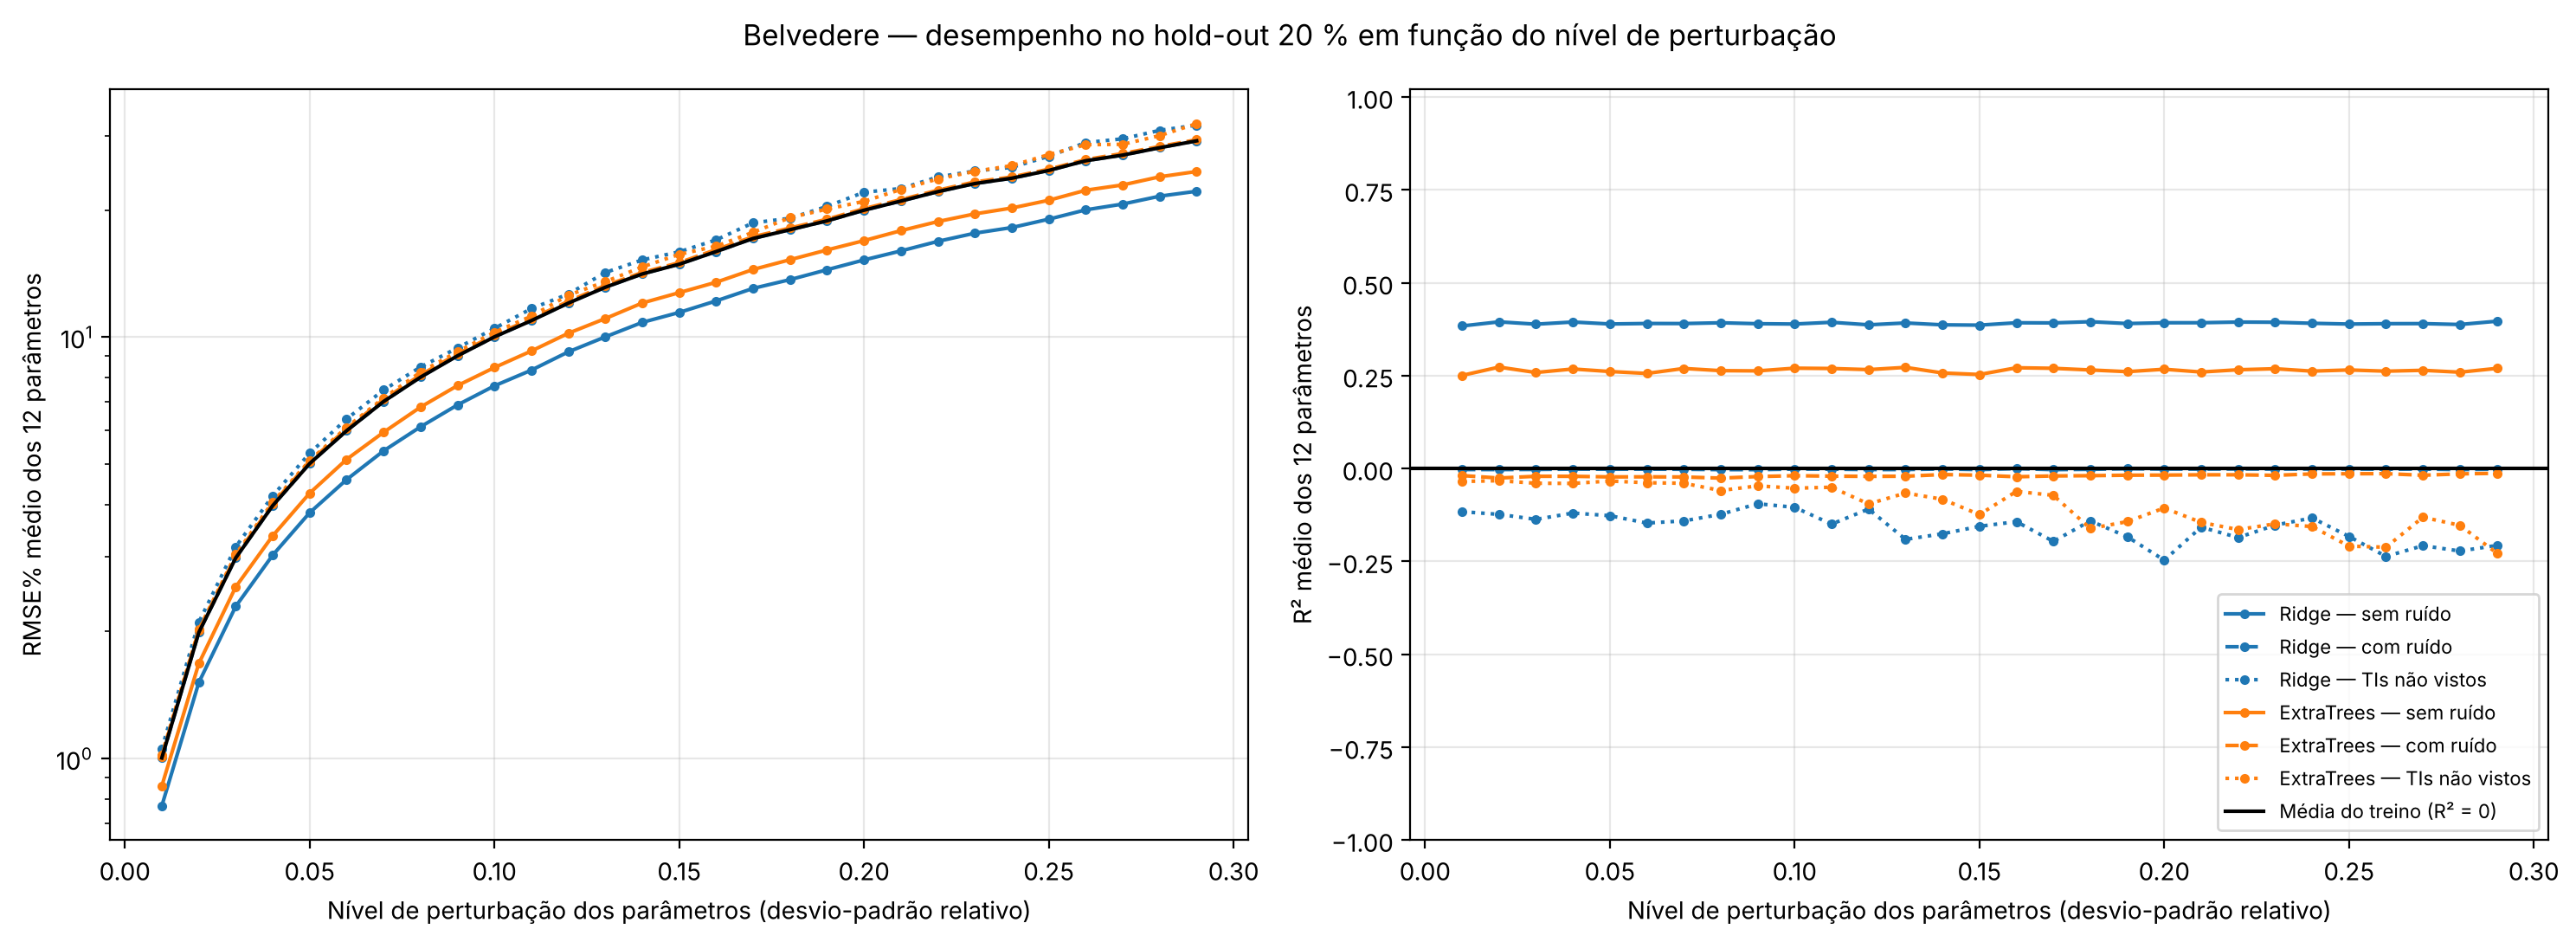

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
styles = {'sem ruído': '-', 'com ruído': '--', 'TIs não vistos': ':'}
colors = {'Ridge': 'tab:blue', 'ExtraTrees': 'tab:orange'}

for name in sweep_models:
    for label, ls in styles.items():
        axes[0].plot(df_sweep.index, df_sweep[f'{name} {label} RMSE%'], ls=ls, color=colors[name],
                     marker='o', ms=3, label=f'{name} — {label}')
        axes[1].plot(df_sweep.index, df_sweep[f'{name} {label} R²'], ls=ls, color=colors[name],
                     marker='o', ms=3, label=f'{name} — {label}')
axes[0].plot(df_sweep.index, df_sweep['Média RMSE%'], color='black', lw=1.5, label='Média do treino (referência)')
axes[1].axhline(0, color='black', lw=1.5, label='Média do treino (R² = 0)')

axes[0].set_ylabel('RMSE% médio dos 12 parâmetros')
axes[0].set_yscale('log')
axes[1].set_ylabel('R² médio dos 12 parâmetros')
axes[1].set_ylim(-1, 1.02)
for ax in axes:
    ax.set_xlabel('Nível de perturbação dos parâmetros (desvio-padrão relativo)')
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8, loc='lower right')
plt.suptitle('Belvedere — desempenho no hold-out 20 % em função do nível de perturbação', fontsize=12)
plt.tight_layout()
plt.show()